# **Imports and Installations**

In [ ]:
!pip install -q einops decord
!pip install -q timm==0.4.12

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 19.6 MB/s eta 0:00:00


In [ ]:
!git clone https://github.com/sunlicai/MAE-DFER.git /content/MAE-DFER
import sys
sys.path.insert(0, '/content/MAE-DFER')
print('MAE-DFER repo ready.')

Cloning into '/content/MAE-DFER'...
remote: Enumerating objects: 259, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 259 (delta 50), reused 17 (delta 17), pack-reused 181 (from 1)
Receiving objects: 100% (259/259), 16.52 MiB | 16.28 MiB/s, done.
Resolving deltas: 100% (98/98), done.
MAE-DFER repo ready.


In [ ]:
# ── CELL 2: Patch LGBlock gamma branch ───────────────────────────────────────
import modeling_finetune
from einops import rearrange

def lgblock_forward_patched(self, x, b):
    bn = x.shape[0]
    n  = bn // b

    if self.gamma_1 is None:
        if self.first_attn_type == 'self':
            x = x + self.drop_path(self.first_attn(self.first_attn_norm0(x)))
        else:
            x[:,:1] = x[:,:1] + self.drop_path(
                self.first_attn(
                    self.first_attn_norm0(x[:,:1]),
                    context=self.first_attn_norm1(x[:,1:])
                )
            )

        if not self.no_second:
            messenger_tokens = rearrange(x[:,0].clone(), '(b n) c -> b n c', b=b)
            messenger_tokens = messenger_tokens + self.drop_path(
                self.second_attn(self.second_attn_norm0(messenger_tokens))
            )
            x[:,0] = rearrange(messenger_tokens, 'b n c -> (b n) c')
        else:
            messenger_tokens = rearrange(x[:,0].clone(), '(b n) c -> b n c', b=b)

        if not self.no_third:
            if self.third_attn_type == 'self':
                x = x + self.drop_path(self.third_attn(self.third_attn_norm0(x)))
            else:
                local_tokens = rearrange(x[:,1:].clone(), '(b n) s c -> b (n s) c', b=b)
                local_tokens = local_tokens + self.drop_path(
                    self.third_attn(
                        self.third_attn_norm0(local_tokens),
                        context=self.third_attn_norm1(messenger_tokens)
                    )
                )
                x[:,1:] = rearrange(local_tokens, 'b (n s) c -> (b n) s c', n=n)

        x = x + self.drop_path(self.mlp(self.norm2(x)))

    else:
        # ── Gamma scaling branch ──────────────────────────────────────────────
        if self.first_attn_type == 'self':
            x = x + self.drop_path(
                self.gamma_0 * self.first_attn(self.first_attn_norm0(x))
            )
        else:
            x[:,:1] = x[:,:1] + self.drop_path(
                self.gamma_0 * self.first_attn(
                    self.first_attn_norm0(x[:,:1]),
                    context=self.first_attn_norm1(x[:,1:])
                )
            )

        if not self.no_second:
            messenger_tokens = rearrange(x[:,0].clone(), '(b n) c -> b n c', b=b)
            messenger_tokens = messenger_tokens + self.drop_path(
                self.gamma_1 * self.second_attn(self.second_attn_norm0(messenger_tokens))
            )
            x[:,0] = rearrange(messenger_tokens, 'b n c -> (b n) c')
        else:
            messenger_tokens = rearrange(x[:,0].clone(), '(b n) c -> b n c', b=b)

        if not self.no_third:
            if self.third_attn_type == 'self':
                x = x + self.drop_path(
                    self.gamma_1 * self.third_attn(self.third_attn_norm0(x))
                )
            else:
                local_tokens = rearrange(x[:,1:].clone(), '(b n) s c -> b (n s) c', b=b)
                local_tokens = local_tokens + self.drop_path(
                    self.gamma_1 * self.third_attn(
                        self.third_attn_norm0(local_tokens),
                        context=self.third_attn_norm1(messenger_tokens)
                    )
                )
                x[:,1:] = rearrange(local_tokens, 'b (n s) c -> (b n) s c', n=n)

        x = x + self.drop_path(self.gamma_2 * self.mlp(self.norm2(x)))

    return x


modeling_finetune.LGBlock.forward = lgblock_forward_patched
print('LGBlock.forward patched — gamma branch now implemented.')

LGBlock.forward patched — gamma branch now implemented.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import random
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.notebook import tqdm
from functools import partial

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import cv2
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# MAE-DFER imports
import modeling_finetune
from timm.models import create_model

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU:   {torch.cuda.get_device_name(0)}')
    print(f'VRAM:  {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('WARNING: No GPU — go to Runtime > Change runtime type > T4 GPU')

Device: cuda
GPU:   Tesla T4
VRAM:  15.6 GB


# **Config**

In [ ]:
# ── Paths ─────────────────────────────────────────────────────────────────────
LABEL_PATH      = '/content/label_FULLY_PRUNED.csv'
RAW_VIDEO_DIR   = '/content/Dataset/Raw-Cropped-FULL/'
CKPT_DIR        = '/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Checkpoints/'
PRETRAINED_CKPT = '/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Pretrained/checkpoint-49.pth'

# ── Model ─────────────────────────────────────────────────────────────────────
NUM_FRAMES  = 16
IMAGE_SIZE  = 160
HIDDEN_SIZE = 512

# ── Target columns ────────────────────────────────────────────────────────────
EMOTION_COLS = ['happy', 'sad', 'anger', 'fear', 'disgust', 'surprise']
TARGET_COLS  = EMOTION_COLS + ['sentiment']
NUM_TARGETS  = 7

SENTIMENT_WEIGHT = 1.0

# ── Training ──────────────────────────────────────────────────────────────────
BATCH_SIZE   = 4
ACCUM_STEPS  = 4       # Effective batch = 16
NUM_EPOCHS   = 10
LR           = 1e-4
WEIGHT_DECAY = 1e-2
NUM_WORKERS  = 2

os.makedirs(CKPT_DIR, exist_ok=True)
print('Config set.')

Config set.


# **Directories and File Paths**

In [ ]:
DRIVE_DS_ZIP_PATH = '/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw-Cropped-FULL.zip'
DRIVE_LABEL_PATH  = '/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_FULLY_PRUNED.csv'
LOCAL_DS_ZIP_PATH = '/content/Raw-Cropped-FULL.zip'

!cp "{DRIVE_LABEL_PATH}" "{LABEL_PATH}"
!cp "{DRIVE_DS_ZIP_PATH}" "{LOCAL_DS_ZIP_PATH}"

In [ ]:
os.makedirs('/content/Dataset/', exist_ok=True)
!unzip -q "{LOCAL_DS_ZIP_PATH}" -d "/content/Dataset/"
print('Done.')

Done.


In [ ]:
paths = [
    LABEL_PATH,
    RAW_VIDEO_DIR,
    CKPT_DIR,
    PRETRAINED_CKPT,
    DRIVE_LABEL_PATH,
]

for path in paths:
    if not Path(path).exists():
        print(f'DOES NOT EXIST: {path}')
    else:
        print(f'EXISTS:         {path}')

EXISTS:         /content/label_FULLY_PRUNED.csv
EXISTS:         /content/Dataset/Raw-Cropped-FULL/
EXISTS:         /content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Checkpoints/
EXISTS:         /content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Pretrained/checkpoint-49.pth
EXISTS:         /content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_FULLY_PRUNED.csv


# **Load Labels**

In [ ]:
df = pd.read_csv(LABEL_PATH)
df['video_id'] = df['video_id'].astype(str)
df['clip_id']  = df['clip_id'].astype(str)

# Emotions: [0, 3] | Sentiment: [-3, 3]
raw_path     = Path(RAW_VIDEO_DIR)
df['path']   = df.apply(lambda r: str(raw_path / r['video_id'] / f"{r['clip_id']}.mp4"), axis=1)
df['exists'] = df['path'].apply(lambda p: Path(p).exists())

missing = (~df['exists']).sum()
print(f'Missing files: {missing} — dropping them.')
df = df[df['exists']].reset_index(drop=True)
print(f'Usable clips:  {len(df):,}')
df[TARGET_COLS].describe().round(4)

Missing files: 0 — dropping them.
Usable clips:  19,970


,happy,sad,anger,fear,disgust,surprise,sentiment
count,19970.0000,19970.0000,19970.0000,19970.0000,19970.0000,19970.0000,19970.0000
mean,0.4781,0.1579,0.1526,0.0475,0.1182,0.0423,0.1524
std,0.6281,0.3244,0.3569,0.1665,0.3169,0.1544,1.1105
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-3.0000
25%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.3333
50%,0.3333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,0.6667,0.3333,0.0000,0.0000,0.0000,0.0000,1.0000
max,3.0000,3.0000,3.0000,2.6667,3.0000,1.6667,3.0000


# **Train Val Test Split**


In [ ]:
train_df = df[df['mode'] == 'train'].reset_index(drop=True)
val_df   = df[df['mode'] == 'valid'].reset_index(drop=True)
test_df  = df[df['mode'] == 'test'].reset_index(drop=True)

print(f'Train: {len(train_df):,} ({100*len(train_df)/len(df):.1f}%)')
print(f'Val:   {len(val_df):,} ({100*len(val_df)/len(df):.1f}%)')
print(f'Test:  {len(test_df):,} ({100*len(test_df)/len(df):.1f}%)')
print(f'Total: {len(train_df) + len(val_df) + len(test_df):,}')

Train: 14,179 (71.0%)
Val:   1,671 (8.4%)
Test:  4,120 (20.6%)
Total: 19,970


# **Dataset Class**

In [ ]:
MEAN = [0.5, 0.5, 0.5]
STD  = [0.5, 0.5, 0.5]

class MOSEIVideoDataset(Dataset):
    def __init__(self, dataframe, num_frames=16, image_size=160, augment=False): # Image size is 160x160, not 240x240
        self.df         = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.image_size = image_size
        self.augment    = augment
        self.mean       = np.array(MEAN, dtype=np.float32)
        self.std        = np.array(STD,  dtype=np.float32)

    def __len__(self):
        return len(self.df)

    def _load_frames(self, video_path):
        cap   = cv2.VideoCapture(video_path)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total < 1:
            cap.release()
            return [np.zeros((self.image_size, self.image_size, 3), dtype=np.uint8)
                    for _ in range(self.num_frames)]
        indices = np.linspace(0, total - 1, self.num_frames, dtype=int)
        frames  = []
        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ok, frame = cap.read()
            if ok:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame = cv2.resize(frame, (self.image_size, self.image_size))
            else:
                frame = np.zeros((self.image_size, self.image_size, 3), dtype=np.uint8)
            frames.append(frame)
        cap.release()
        return frames

    def _normalise(self, frames):
        result = []
        for f in frames:
            f = f.astype(np.float32) / 255.0
            f = (f - self.mean) / self.std
            result.append(f)
        return result

    def _augment(self, frames):
        if random.random() > 0.5:
            frames = [np.fliplr(f) for f in frames]
        return frames

    def __getitem__(self, idx):
        row    = self.df.iloc[idx]
        frames = self._load_frames(row['path'])
        if self.augment:
            frames = self._augment(frames)
        frames = self._normalise(frames)

        # [T, H, W, C] → [C, T, H, W]
        video  = np.stack(frames, axis=0)
        video  = torch.from_numpy(video).permute(3, 0, 1, 2)

        labels = torch.tensor(row[TARGET_COLS].values.astype(np.float32),
                              dtype=torch.float32)
        return video, labels

In [ ]:
train_dataset = MOSEIVideoDataset(train_df, NUM_FRAMES, IMAGE_SIZE, augment=True)
val_dataset   = MOSEIVideoDataset(val_df,   NUM_FRAMES, IMAGE_SIZE, augment=False)
test_dataset  = MOSEIVideoDataset(test_df,  NUM_FRAMES, IMAGE_SIZE, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f'Train batches: {len(train_loader):,}')
print(f'Val batches:   {len(val_loader):,}')
print(f'Test batches:  {len(test_loader):,}')

# Sanity check
video, labels = next(iter(train_loader))
print(f'\nvideo shape  : {video.shape}')   # expect [4, 3, 16, 160, 160]
print(f'labels shape : {labels.shape}')   # expect [4, 7]

Train batches: 3,545
Val batches:   418
Test batches:  1,030

video shape  : torch.Size([4, 3, 16, 160, 160])
labels shape : torch.Size([4, 7])


# **Model - MAEDFER**

In [ ]:
class MAEDFERForEmotionRegression(nn.Module):
    def __init__(self, pretrained_ckpt, num_targets=7, dropout=0.3):
        super().__init__()

        self.backbone = create_model(
            'vit_base_dim512_no_depth_patch16_160',
            pretrained=False,
            num_classes=7,
            all_frames=NUM_FRAMES,
            tubelet_size=2,
            use_mean_pooling=True,
            attn_type='local_global',
            lg_region_size=(2, 5, 10),
            lg_first_attn_type='self',
            lg_third_attn_type='cross',
            lg_attn_param_sharing_first_third=False,
            lg_attn_param_sharing_all=False,
            lg_classify_token_type='org',
            lg_no_second=False,
            lg_no_third=False,
            drop_path_rate=0.1,
            init_values=0.1,
        )
        self.backbone.head = nn.Identity()

        ckpt       = torch.load(pretrained_ckpt, map_location='cpu', weights_only=False)
        state_dict = ckpt['model'] if 'model' in ckpt else ckpt
        msg        = self.backbone.load_state_dict(state_dict, strict=False)
        print(f'Pre-trained weights loaded.')
        print(f'  Missing keys:    {len(msg.missing_keys)}')
        print(f'  Unexpected keys: {len(msg.unexpected_keys)}')

        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(HIDDEN_SIZE, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_targets)
        )

    def forward(self, x):
        features  = self.backbone(x)
        logits    = self.head(features)
        emotions  = torch.clamp(torch.relu(logits[:, :6]), 0.0, 3.0)
        sentiment = torch.tanh(logits[:, 6:7]) * 3.0
        return torch.cat([emotions, sentiment], dim=1)


model = MAEDFERForEmotionRegression(PRETRAINED_CKPT, NUM_TARGETS).to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal params:     {total_params:,}')
print(f'Trainable params: {trainable_params:,}')

==> Note: Use 'local_global' for compute reduction (lg_region_size=(2, 5, 10),lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=org,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
Pre-trained weights loaded.
  Missing keys:    425
  Unexpected keys: 575

Total params:     64,005,639
Trainable params: 64,005,639


In [ ]:
class EmotionLoss(nn.Module):
    """
    Huber loss for emotion and sentiment targets.
    Sentiment uses standard unweighted Huber loss.
    """
    def __init__(self, sentiment_weight=1.0, delta=0.5):
        super().__init__()
        self.sentiment_weight = sentiment_weight
        self.delta            = delta

    def forward(self, preds, targets):
        emot_preds = preds[:, :6]
        sent_preds = preds[:, 6]
        emot_tgts  = targets[:, :6]
        sent_tgts  = targets[:, 6]

        emot_loss = F.huber_loss(emot_preds, emot_tgts,
                                 delta=self.delta, reduction='mean')
        sent_loss = F.huber_loss(sent_preds, sent_tgts,
                                 delta=self.delta, reduction='mean')

        return emot_loss + self.sentiment_weight * sent_loss


criterion = EmotionLoss(
    sentiment_weight=SENTIMENT_WEIGHT,
    delta=0.5
)
print('Loss function ready.')

Loss function ready.


In [ ]:
optimizer = torch.optim.AdamW([
    {'params': model.backbone.parameters(), 'lr': LR * 0.1},  # 1e-5
    {'params': model.head.parameters(),     'lr': LR},         # 1e-4
], weight_decay=WEIGHT_DECAY)

total_steps  = (len(train_loader) // ACCUM_STEPS) * NUM_EPOCHS
warmup_steps = total_steps // 10

def lr_lambda(step):
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return max(0.0, 0.5 * (1.0 + np.cos(np.pi * progress)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

print(f'Total steps  : {total_steps:,}')
print(f'Warmup steps : {warmup_steps:,}')

Total steps  : 8,860
Warmup steps : 886


# **Evaluation Metrics**

In [ ]:
def compute_metrics(all_preds, all_labels):
    metrics = {}
    maes, pearsonrs = [], []
    for i, col in enumerate(TARGET_COLS):
        preds  = all_preds[:, i]
        labels = all_labels[:, i]
        mae    = np.abs(preds - labels).mean()
        try:
            r, _ = pearsonr(preds, labels)
        except Exception:
            r = 0.0
        metrics[f'mae_{col}'] = mae
        metrics[f'r_{col}']   = r
        maes.append(mae)
        pearsonrs.append(r)
    metrics['mae_avg'] = np.mean(maes)
    metrics['r_avg']   = np.mean(pearsonrs)
    sent_pred          = (all_preds[:, -1]  > 0).astype(int)
    sent_label         = (all_labels[:, -1] > 0).astype(int)
    metrics['sentiment_acc'] = (sent_pred == sent_label).mean()
    return metrics


def print_metrics(metrics, split='Val'):
    print(f'\n── {split} ───────────────────────────────────────')
    print(f'  Avg MAE  : {metrics["mae_avg"]:.4f}')
    print(f'  Avg r    : {metrics["r_avg"]:.4f}')
    print(f'  Sent acc : {metrics["sentiment_acc"]:.4f}')
    print('  Per-target:')
    for col in TARGET_COLS:
        print(f'    {col:<10}  MAE={metrics[f"mae_{col}"]:.4f}  r={metrics[f"r_{col}"]:.4f}')

# **Train and eval functions**

In [ ]:
def train_one_epoch(model, loader, optimizer, scheduler, criterion, accum_steps):
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()
    for step, (video, labels) in enumerate(tqdm(loader, desc='  Train', leave=False)):
        video  = video.to(DEVICE)
        labels = labels.to(DEVICE)
        preds  = model(video)
        loss   = criterion(preds, labels) / accum_steps
        loss.backward()
        if (step + 1) % accum_steps == 0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
        total_loss += loss.item() * accum_steps
    return total_loss / len(loader)


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    for video, labels in tqdm(loader, desc='  Eval', leave=False):
        video  = video.to(DEVICE)
        labels = labels.to(DEVICE)
        preds  = model(video)
        total_loss += criterion(preds, labels).item()
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
    all_preds  = np.vstack(all_preds)
    all_labels = np.vstack(all_labels)
    return total_loss / len(loader), compute_metrics(all_preds, all_labels)

# **Training loop**

In [ ]:
# Training loop
best_ckpt    = os.path.join(CKPT_DIR, 'best_model.pt')
history      = {'train_loss': [], 'val_loss': [], 'val_mae': [], 'val_r': []}
best_val_mae = float('inf')
patience     = 3        # stop if no improvement for 3 epochs
patience_cnt = 0

print(f'Starting fine-tuning — {NUM_EPOCHS} epochs')
print(f'Effective batch size : {BATCH_SIZE * ACCUM_STEPS}')
print(f'Checkpoints → {CKPT_DIR}\n')

for epoch in range(1, NUM_EPOCHS + 1):
    print(f'Epoch {epoch}/{NUM_EPOCHS}')
    train_loss            = train_one_epoch(model, train_loader, optimizer,
                                            scheduler, criterion, ACCUM_STEPS)
    val_loss, val_metrics = evaluate(model, val_loader, criterion)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_mae'].append(val_metrics['mae_avg'])
    history['val_r'].append(val_metrics['r_avg'])

    print(f'  Train loss : {train_loss:.4f}')
    print(f'  Val loss   : {val_loss:.4f}')
    print_metrics(val_metrics, split=f'Val epoch {epoch}')

    # Save every epoch checkpoint
    torch.save({
        'epoch':     epoch,
        'model':     model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict(),
        'val_mae':   val_metrics['mae_avg'],
        'history':   history,
    }, os.path.join(CKPT_DIR, f'epoch_{epoch:02d}.pt'))

    # Save best and check early stopping
    if val_metrics['mae_avg'] < best_val_mae:
        best_val_mae = val_metrics['mae_avg']
        patience_cnt = 0
        torch.save(model.state_dict(), best_ckpt)
        print(f'  ✓ New best saved (MAE={best_val_mae:.4f})')
    else:
        patience_cnt += 1
        print(f'  No improvement — patience {patience_cnt}/{patience}')
        if patience_cnt >= patience:
            print(f'\nEarly stopping at epoch {epoch} — best MAE: {best_val_mae:.4f}')
            break

print(f'\nDone. Best val MAE: {best_val_mae:.4f}')

Starting fine-tuning — 10 epochs
Effective batch size : 16
Checkpoints → /content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Checkpoints/

Epoch 1/10


  Train:   0%|          | 0/3545 [00:00<?, ?it/s]

  Eval:   0%|          | 0/418 [00:00<?, ?it/s]

  Train loss : 0.3949
  Val loss   : 0.3332

── Val epoch 1 ───────────────────────────────────────
  Avg MAE  : 0.2545
  Avg r    : nan
  Sent acc : 0.4877
  Per-target:
    happy       MAE=0.4057  r=-0.0186
    sad         MAE=0.2044  r=0.0732
    anger       MAE=0.1633  r=-0.0399
    fear        MAE=0.0487  r=nan
    disgust     MAE=0.1131  r=0.0237
    surprise    MAE=0.0454  r=nan
    sentiment   MAE=0.8007  r=0.0428
  ✓ New best saved (MAE=0.2545)
Epoch 2/10


  Train:   0%|          | 0/3545 [00:00<?, ?it/s]

  Eval:   0%|          | 0/418 [00:00<?, ?it/s]

... (3 outputs left out)

  Train loss : 0.3647
  Val loss   : 0.3230

── Val epoch 3 ───────────────────────────────────────
  Avg MAE  : 0.2607
  Avg r    : 0.0235
  Sent acc : 0.5236
  Per-target:
    happy       MAE=0.4059  r=0.0194
    sad         MAE=0.2246  r=0.0913
    anger       MAE=0.1851  r=-0.0330
    fear        MAE=0.0569  r=0.0124
    disgust     MAE=0.1382  r=0.0240
    surprise    MAE=0.0454  r=-0.0275
    sentiment   MAE=0.7690  r=0.0778
  No improvement — patience 2/3
Epoch 4/10


  Train:   0%|          | 0/3545 [00:00<?, ?it/s]

  Eval:   0%|          | 0/418 [00:00<?, ?it/s]

  Train loss : 0.3634
  Val loss   : 0.3237

── Val epoch 4 ───────────────────────────────────────
  Avg MAE  : 0.2672
  Avg r    : 0.0472
  Sent acc : 0.5266
  Per-target:
    happy       MAE=0.4030  r=0.0854
    sad         MAE=0.2231  r=0.0904
    anger       MAE=0.1928  r=-0.0206
    fear        MAE=0.0619  r=0.0525
    disgust     MAE=0.1546  r=0.0047
    surprise    MAE=0.0657  r=0.0569
    sentiment   MAE=0.7693  r=0.0609
  No improvement — patience 3/3

Early stopping at epoch 4 — best MAE: 0.2545

Done. Best val MAE: 0.2545


In [ ]:
model.load_state_dict(torch.load(best_ckpt, map_location=DEVICE, weights_only=False))
test_loss, test_metrics = evaluate(model, test_loader, criterion)

print(f'Test loss: {test_loss:.4f}')
print_metrics(test_metrics, split='Test')

  Eval:   0%|          | 0/1030 [00:00<?, ?it/s]

Test loss: 0.3698

── Test ───────────────────────────────────────
  Avg MAE  : 0.2742
  Avg r    : nan
  Sent acc : 0.4932
  Per-target:
    happy       MAE=0.4460  r=0.0912
    sad         MAE=0.1838  r=0.0824
    anger       MAE=0.1967  r=0.0539
    fear        MAE=0.0444  r=nan
    disgust     MAE=0.1371  r=0.0917
    surprise    MAE=0.0458  r=nan
    sentiment   MAE=0.8655  r=0.0544


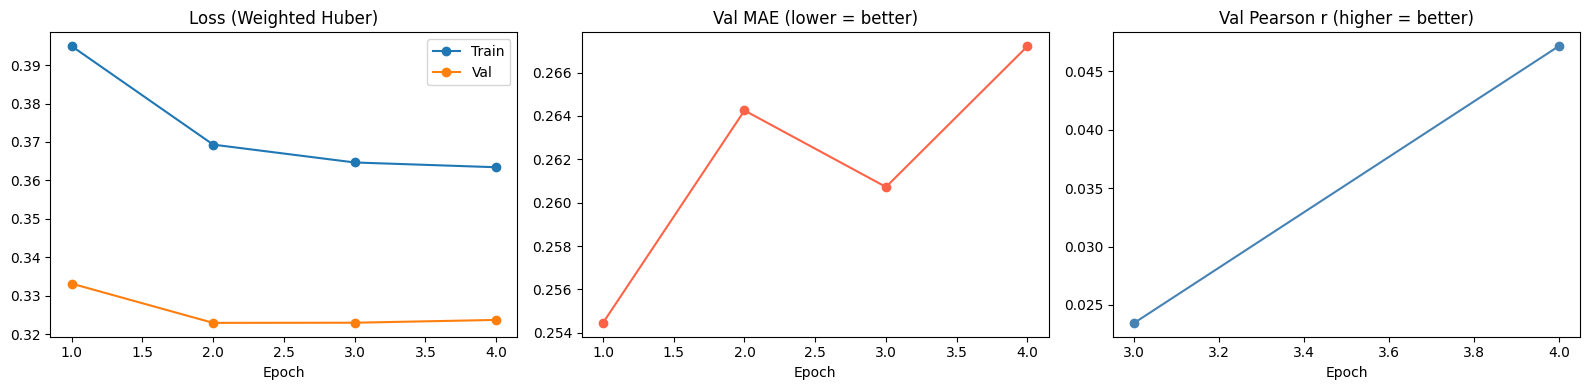

In [ ]:
epochs = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(epochs, history['train_loss'], label='Train', marker='o')
axes[0].plot(epochs, history['val_loss'],   label='Val',   marker='o')
axes[0].set_title('Loss (Weighted Huber)'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(epochs, history['val_mae'], color='tomato', marker='o')
axes[1].set_title('Val MAE (lower = better)'); axes[1].set_xlabel('Epoch')

axes[2].plot(epochs, history['val_r'], color='steelblue', marker='o')
axes[2].set_title('Val Pearson r (higher = better)'); axes[2].set_xlabel('Epoch')

plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

# **Resume from checkpoint (If colab disconnected)**

In [ ]:
RESUME_FROM = os.path.join(CKPT_DIR, 'epoch_x.pt')  # change epoch number

ckpt = torch.load(RESUME_FROM, map_location=DEVICE)
model.load_state_dict(ckpt['model'])
optimizer.load_state_dict(ckpt['optimizer'])
scheduler.load_state_dict(ckpt['scheduler'])
history     = ckpt['history']
start_epoch = ckpt['epoch'] + 1
print(f'Resumed from epoch {ckpt["epoch"]} — continuing from epoch {start_epoch}')